# 14. Noise Regression: Diurnal & Weekly Cyclical Profiles

**Topic**: Supervised linear regression models predicting hourly Brooklyn noise complaints from cyclical diurnal (hour-of-day) and weekly (day-of-week) calendar features.

- **Inputs**:
  - `data/processed/complaints_clean.csv` (236,507 complaints, Brooklyn 2025-2026)
- **Outputs**:
  - `models/noise_model.joblib` (frozen linear regression bundle for hourly noise)
  - `report/figures/14_hour_profile.png`
  - `report/figures/14_pred_vs_actual.png`
  - `report/figures/14_residuals.png`
- **Runtime**: < 30 seconds

In [1]:
import sys; from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "environment.yml").exists()); sys.path.insert(0, str(ROOT))
from src.nbutils import Checker
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from datetime import datetime
import sklearn

# Configuration Flags
RUN_HEAVY = False
RUN_API = False


In [2]:
# Section a: Data Loading & Diurnal Hourly Grid Construction
from src.models.regression import build_noise_hourly

clean_csv_path = ROOT / "data/processed/complaints_clean.csv"
df = pd.read_csv(
    clean_csv_path,
    dtype={"id": str, "resolution_id": str},
    keep_default_na=False,
)

noise_raw = df[df["group"] == "noise"].copy()
print(f"Loaded {len(df):,} total complaints; {len(noise_raw):,} belong to 'noise' group.")

# Construct hourly grid (excluding midnight timestamp placeholders)
hourly_df, meta = build_noise_hourly(noise_raw, start_date="2025-11-01", end_date="2026-10-31")
feature_cols = meta["hour_features"] + meta["weekday_features"]

print(f"\n--- Hourly Grid Audit ---")
print(f"Total noise rows: {meta['n_total_noise']:,}")
print(f"Excluded midnight placeholder rows: {meta['n_excluded_midnight']:,} ({meta['share_excluded']:.4%})")
print(f"Complete grid rows (365 days x 24 hours): {len(hourly_df):,} (Expected: 8,760)")
print(f"Zero-count hours in grid: {meta['zero_count_hours']:,} (Expected: 1)")

Loaded 236,507 total complaints; 211,843 belong to 'noise' group.
build_noise_hourly: Excluded 11 midnight placeholder rows (0.0052%)
Weekday encoding in complaints_clean.csv: 0=Monday, 1=Tuesday, 2=Wednesday, 3=Thursday, 4=Friday, 5=Saturday, 6=Sunday.


build_noise_hourly: Reindexed to 8,760 hours. Zero-count hours: 1

--- Hourly Grid Audit ---
Total noise rows: 211,843
Excluded midnight placeholder rows: 11 (0.0052%)
Complete grid rows (365 days x 24 hours): 8,760 (Expected: 8,760)
Zero-count hours in grid: 1 (Expected: 1)


In [3]:
# Section b: Model Evaluation Across Chrono 80/20 and Rolling-Origin Monthly Folds
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 1. Chronological 80/20 by date
unique_dates = np.sort(hourly_df["date"].unique())
n_train_dates = int(len(unique_dates) * 0.8)
train_dates = set(unique_dates[:n_train_dates])
test_dates = set(unique_dates[n_train_dates:])

chrono_tr = hourly_df[hourly_df["date"].isin(train_dates)]
chrono_te = hourly_df[hourly_df["date"].isin(test_dates)]

# Models on Chrono split
lr_chrono = LinearRegression().fit(chrono_tr[feature_cols], chrono_tr["count"])
pred_chrono_lr = lr_chrono.predict(chrono_te[feature_cols])
pred_chrono_base = np.full(len(chrono_te), fill_value=chrono_tr["count"].mean())
hour_mean_chrono = chrono_tr.groupby("hour")["count"].mean().to_dict()
pred_chrono_hour = chrono_te["hour"].map(hour_mean_chrono).values

chrono_records = [
    {
        "split": "chrono_80_20",
        "model": "LinearRegression (hour+weekday)",
        "mse": mean_squared_error(chrono_te["count"], pred_chrono_lr),
        "rmse": np.sqrt(mean_squared_error(chrono_te["count"], pred_chrono_lr)),
        "mae": mean_absolute_error(chrono_te["count"], pred_chrono_lr),
        "r2": r2_score(chrono_te["count"], pred_chrono_lr),
        "n_test": len(chrono_te),
    },
    {
        "split": "chrono_80_20",
        "model": "baseline_train_mean",
        "mse": mean_squared_error(chrono_te["count"], pred_chrono_base),
        "rmse": np.sqrt(mean_squared_error(chrono_te["count"], pred_chrono_base)),
        "mae": mean_absolute_error(chrono_te["count"], pred_chrono_base),
        "r2": r2_score(chrono_te["count"], pred_chrono_base),
        "n_test": len(chrono_te),
    },
    {
        "split": "chrono_80_20",
        "model": "hour_only_mean",
        "mse": mean_squared_error(chrono_te["count"], pred_chrono_hour),
        "rmse": np.sqrt(mean_squared_error(chrono_te["count"], pred_chrono_hour)),
        "mae": mean_absolute_error(chrono_te["count"], pred_chrono_hour),
        "r2": r2_score(chrono_te["count"], pred_chrono_hour),
        "n_test": len(chrono_te),
    },
]

# 2. Rolling-origin by month for test months 2026-03 .. 2026-10 (>= 4 months training)
test_months = ["2026-03", "2026-04", "2026-05", "2026-06", "2026-07", "2026-08", "2026-09", "2026-10"]
monthly_records = []
pooled_y = []
pooled_lr = []
pooled_base = []
pooled_hour = []

for m in test_months:
    tr_df = hourly_df[hourly_df["date"] < f"{m}-01"]
    te_df = hourly_df[hourly_df["date"].str.startswith(m)]
    
    y_tr = tr_df["count"].values
    y_te = te_df["count"].values
    
    # Fit models
    lr_m = LinearRegression().fit(tr_df[feature_cols], y_tr)
    p_lr = lr_m.predict(te_df[feature_cols])
    p_base = np.full(len(y_te), fill_value=y_tr.mean())
    h_dict = tr_df.groupby("hour")["count"].mean().to_dict()
    p_hour = te_df["hour"].map(h_dict).values
    
    pooled_y.extend(y_te)
    pooled_lr.extend(p_lr)
    pooled_base.extend(p_base)
    pooled_hour.extend(p_hour)
    
    monthly_records.append({
        "month": m,
        "n_test": len(y_te),
        "mae_lr": mean_absolute_error(y_te, p_lr),
        "r2_lr": r2_score(y_te, p_lr),
        "mae_base": mean_absolute_error(y_te, p_base),
        "r2_base": r2_score(y_te, p_base),
        "mae_hour": mean_absolute_error(y_te, p_hour),
        "r2_hour": r2_score(y_te, p_hour),
    })

# Pooled Rolling Metrics
pooled_y_arr = np.array(pooled_y)
pooled_lr_arr = np.array(pooled_lr)
pooled_base_arr = np.array(pooled_base)
pooled_hour_arr = np.array(pooled_hour)

pooled_records = [
    {
        "model": "LinearRegression (hour+weekday)",
        "mse": mean_squared_error(pooled_y_arr, pooled_lr_arr),
        "rmse": np.sqrt(mean_squared_error(pooled_y_arr, pooled_lr_arr)),
        "mae": mean_absolute_error(pooled_y_arr, pooled_lr_arr),
        "r2": r2_score(pooled_y_arr, pooled_lr_arr),
        "n_test": len(pooled_y_arr),
    },
    {
        "model": "baseline_train_mean",
        "mse": mean_squared_error(pooled_y_arr, pooled_base_arr),
        "rmse": np.sqrt(mean_squared_error(pooled_y_arr, pooled_base_arr)),
        "mae": mean_absolute_error(pooled_y_arr, pooled_base_arr),
        "r2": r2_score(pooled_y_arr, pooled_base_arr),
        "n_test": len(pooled_y_arr),
    },
    {
        "model": "hour_only_mean",
        "mse": mean_squared_error(pooled_y_arr, pooled_hour_arr),
        "rmse": np.sqrt(mean_squared_error(pooled_y_arr, pooled_hour_arr)),
        "mae": mean_absolute_error(pooled_y_arr, pooled_hour_arr),
        "r2": r2_score(pooled_y_arr, pooled_hour_arr),
        "n_test": len(pooled_y_arr),
    },
]

print("=== Chronological 80/20 Test Performance ===")
print(pd.DataFrame(chrono_records).to_string(index=False))

print("\n=== Rolling-Origin Monthly Performance (2026-03 .. 2026-10) ===")
print(pd.DataFrame(monthly_records).to_string(index=False, formatters={
    "mae_lr": "{:.4f}".format, "r2_lr": "{:.4f}".format,
    "mae_base": "{:.4f}".format, "r2_base": "{:.4f}".format,
    "mae_hour": "{:.4f}".format, "r2_hour": "{:.4f}".format,
}))

print("\n=== Pooled Rolling-Origin Performance ===")
print(pd.DataFrame(pooled_records).to_string(index=False))

=== Chronological 80/20 Test Performance ===
       split                           model        mse      rmse       mae        r2  n_test
chrono_80_20 LinearRegression (hour+weekday) 399.408976 19.985219 10.886618  0.487175    1752
chrono_80_20             baseline_train_mean 829.343847 28.798331 16.753401 -0.064845    1752
chrono_80_20                  hour_only_mean 457.891575 21.398401 11.504369  0.412085    1752

=== Rolling-Origin Monthly Performance (2026-03 .. 2026-10) ===
  month  n_test  mae_lr  r2_lr mae_base r2_base mae_hour r2_hour
2026-03     744  7.6499 0.5249  11.6802 -0.0687   8.1074  0.4777
2026-04     720  7.6382 0.5424  11.9904 -0.0600   7.9447  0.4976
2026-05     744 12.8610 0.3385  17.8042 -0.1422  13.4684  0.2844
2026-06     720 10.5828 0.4954  17.2858 -0.0814  11.1538  0.4359
2026-07     744  8.2338 0.6055  14.8932 -0.0136   9.0413  0.5184
2026-08     744  9.8874 0.5255  16.2437 -0.0315  11.3640  0.4114
2026-09     720 11.3277 0.4600  17.0561 -0.0521  11.6294  0

In [4]:
# Section c: Sensitivity Analysis (Midnight Inclusion & Outlier Coordinates)
def run_noise_pipeline(df_sub, include_midnight=False):
    if not include_midnight:
        df_valid = df_sub[~df_sub["is_midnight_timestamp"].astype(bool)].copy()
    else:
        df_valid = df_sub.copy()
        
    counts = df_valid.groupby(["date", "hour"]).size().reset_index(name="count")
    all_dates = pd.date_range("2025-11-01", "2026-10-31", freq="D").strftime("%Y-%m-%d")
    all_hours = list(range(24))
    grid = pd.MultiIndex.from_product([all_dates, all_hours], names=["date", "hour"]).to_frame().reset_index(drop=True)
    m_df = grid.merge(counts, on=["date", "hour"], how="left")
    m_df["count"] = m_df["count"].fillna(0).astype(int)
    m_df["dt"] = pd.to_datetime(m_df["date"])
    m_df["weekday"] = m_df["dt"].dt.day_of_week
    for h in range(1, 24):
        m_df[f"hour_{h}"] = (m_df["hour"] == h).astype(float)
    for w in range(1, 7):
        m_df[f"weekday_{w}"] = (m_df["weekday"] == w).astype(float)
        
    f_cols = [f"hour_{h}" for h in range(1, 24)] + [f"weekday_{w}" for w in range(1, 7)]
    
    # Full span fit
    lr_all = LinearRegression().fit(m_df[f_cols], m_df["count"])
    intercept_h0 = float(lr_all.intercept_)
    
    # Chrono 80/20 MAE
    u_dates = np.sort(m_df["date"].unique())
    n_tr = int(len(u_dates) * 0.8)
    tr_d = set(u_dates[:n_tr])
    te_d = set(u_dates[n_tr:])
    tr = m_df[m_df["date"].isin(tr_d)]
    te = m_df[m_df["date"].isin(te_d)]
    lr_c = LinearRegression().fit(tr[f_cols], tr["count"])
    chrono_mae = float(mean_absolute_error(te["count"], lr_c.predict(te[f_cols])))
    
    # Pooled rolling MAE
    p_y, p_pred = [], []
    for mo in test_months:
        tr_m = m_df[m_df["date"] < f"{mo}-01"]
        te_m = m_df[m_df["date"].str.startswith(mo)]
        lr_mo = LinearRegression().fit(tr_m[f_cols], tr_m["count"])
        p_y.extend(te_m["count"].values)
        p_pred.extend(lr_mo.predict(te_m[f_cols]))
    rolling_mae = float(mean_absolute_error(p_y, p_pred))
    
    return intercept_h0, chrono_mae, rolling_mae

# 1. Primary
h0_pri, c_mae_pri, r_mae_pri = run_noise_pipeline(noise_raw, include_midnight=False)

# 2. With midnight included
h0_mid, c_mae_mid, r_mae_mid = run_noise_pipeline(noise_raw, include_midnight=True)

# 3. With top 5 coordinates (>1000 complaints) removed
loc_counts = noise_raw.groupby(["lat", "lon"]).size()
top5_coords = loc_counts[loc_counts > 1000].index
noise_no_top5 = noise_raw[~noise_raw.set_index(["lat", "lon"]).index.isin(top5_coords)]
h0_no5, c_mae_no5, r_mae_no5 = run_noise_pipeline(noise_no_top5, include_midnight=False)

sensitivity_df = pd.DataFrame([
    {
        "pipeline": "Primary (Midnight Excluded)",
        "hour_0_intercept": h0_pri,
        "chrono_mae": c_mae_pri,
        "rolling_mae": r_mae_pri,
        "diff_h0_vs_pri": 0.0,
        "diff_rolling_mae_vs_pri": 0.0,
    },
    {
        "pipeline": "Sensitivity: All Rows (Midnight Included)",
        "hour_0_intercept": h0_mid,
        "chrono_mae": c_mae_mid,
        "rolling_mae": r_mae_mid,
        "diff_h0_vs_pri": h0_mid - h0_pri,
        "diff_rolling_mae_vs_pri": r_mae_mid - r_mae_pri,
    },
    {
        "pipeline": "Sensitivity: Drop Top 5 Coordinates (>1000 rows)",
        "hour_0_intercept": h0_no5,
        "chrono_mae": c_mae_no5,
        "rolling_mae": r_mae_no5,
        "diff_h0_vs_pri": h0_no5 - h0_pri,
        "diff_rolling_mae_vs_pri": r_mae_no5 - r_mae_pri,
    },
])

print("=== Sensitivity Analysis Table ===")
print(sensitivity_df.to_string(index=False, formatters={
    "hour_0_intercept": "{:.4f}".format,
    "chrono_mae": "{:.4f}".format,
    "rolling_mae": "{:.4f}".format,
    "diff_h0_vs_pri": "{:+.4f}".format,
    "diff_rolling_mae_vs_pri": "{:+.4f}".format,
}))

=== Sensitivity Analysis Table ===
                                        pipeline hour_0_intercept chrono_mae rolling_mae diff_h0_vs_pri diff_rolling_mae_vs_pri
                     Primary (Midnight Excluded)          46.7049    10.8866      9.7884        +0.0000                 +0.0000
       Sensitivity: All Rows (Midnight Included)          46.7346    10.8885      9.7895        +0.0297                 +0.0011
Sensitivity: Drop Top 5 Coordinates (>1000 rows)          45.4050    10.3195      9.4106        -1.3000                 -0.3778


In [5]:
# Section d: Primary Model Persistence & Prediction Demo
from src.models.regression import predict_noise

# Fit primary model on all 8,760 hours
lr_primary = LinearRegression().fit(hourly_df[feature_cols], hourly_df["count"])

noise_bundle = {
    "model": lr_primary,
    "feature_names": feature_cols,
    "target": "count",
    "sklearn_version": sklearn.__version__,
    "created_date": datetime.now().strftime("%Y-%m-%d"),
    "variant": "primary",
}

models_dir = ROOT / "models"
models_dir.mkdir(parents=True, exist_ok=True)
noise_model_path = models_dir / "noise_model.joblib"
joblib.dump(noise_bundle, noise_model_path)
print(f"Saved frozen noise model to: {noise_model_path.relative_to(ROOT)}")

# Invalidate cache for clean reload
import src.models.regression
src.models.regression._NOISE_MODEL_BUNDLE = None

demo_hours = [3, 9, 14, 20, 23]
demo_weekday = 2  # Wednesday
demo_weekend = 5  # Saturday

print("\n--- Expected Hourly Noise Complaints (Brooklyn City-Wide) ---")
print(f"Wednesday (Weekday = {demo_weekday}):")
for h in demo_hours:
    val = predict_noise(h, demo_weekday, model_path=noise_model_path)
    print(f"  Hour {h:02d}:00 -> Expected Count: {val:.4f}")

print(f"\nSaturday (Weekend = {demo_weekend}):")
for h in demo_hours:
    val = predict_noise(h, demo_weekend, model_path=noise_model_path)
    print(f"  Hour {h:02d}:00 -> Expected Count: {val:.4f}")

Saved frozen noise model to: models\noise_model.joblib

--- Expected Hourly Noise Complaints (Brooklyn City-Wide) ---
Wednesday (Weekday = 2):
  Hour 03:00 -> Expected Count: 9.5477
  Hour 09:00 -> Expected Count: 9.8846
  Hour 14:00 -> Expected Count: 11.1257
  Hour 20:00 -> Expected Count: 30.7230
  Hour 23:00 -> Expected Count: 54.9668

Saturday (Weekend = 5):
  Hour 03:00 -> Expected Count: 24.5677
  Hour 09:00 -> Expected Count: 24.9047
  Hour 14:00 -> Expected Count: 26.1458
  Hour 20:00 -> Expected Count: 45.7430
  Hour 23:00 -> Expected Count: 69.9869


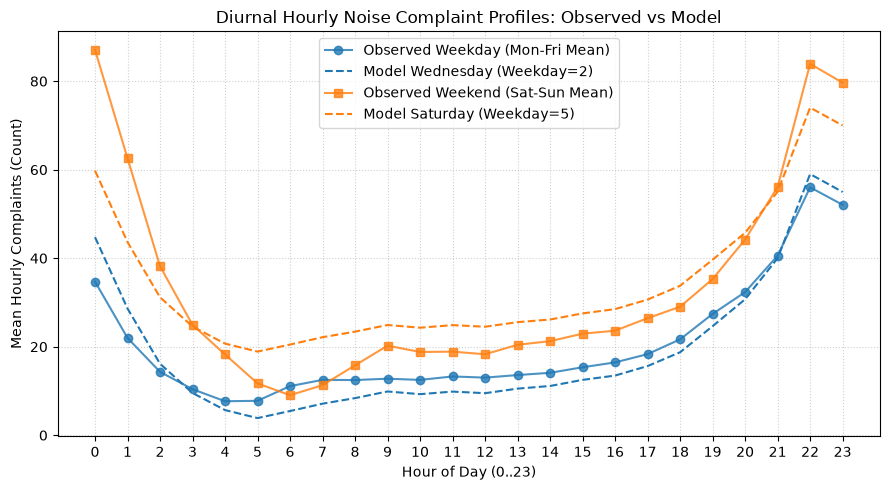

Saved: report\figures\14_hour_profile.png


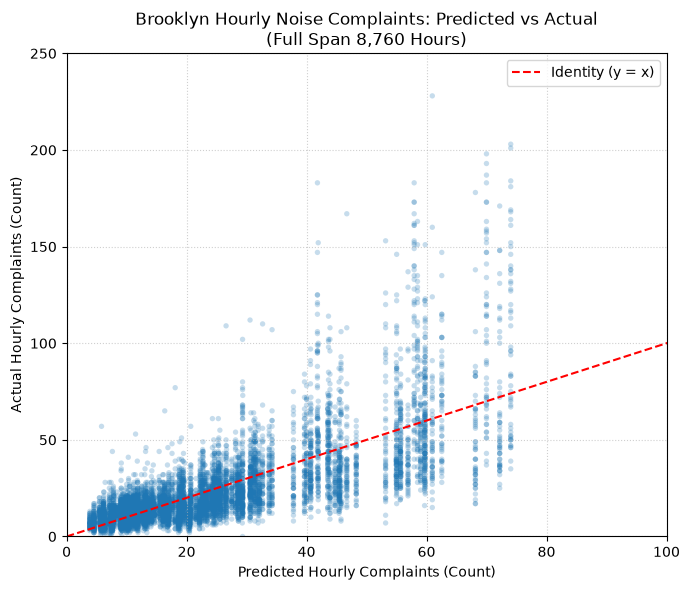

Saved: report\figures\14_pred_vs_actual.png


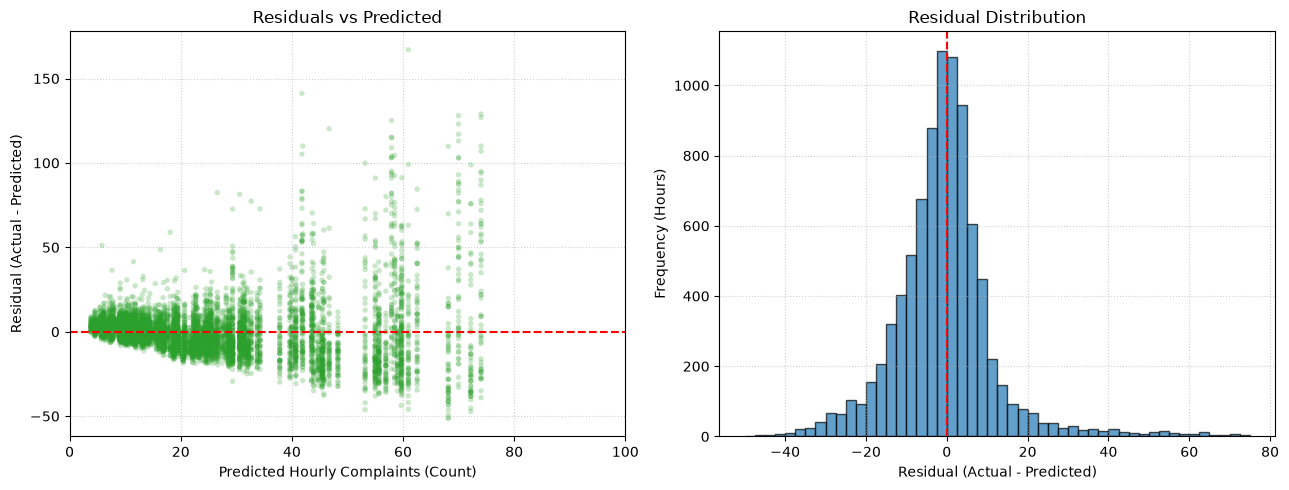

Saved: report\figures\14_residuals.png


In [6]:
# Section e: Visualization & Diagnostic Figures
fig_dir = ROOT / "report/figures"
fig_dir.mkdir(parents=True, exist_ok=True)

# 1. Figure 14: Diurnal Hour Profile by Weekday Group
plt.figure(figsize=(9, 5))
hourly_df["is_weekend"] = hourly_df["weekday"].isin([5, 6])
obs_profile = hourly_df.groupby(["is_weekend", "hour"])["count"].mean()

# Model predictions across 24 hours for Wed (weekday=2) and Sat (weekday=5)
hours_24 = np.arange(24)
pred_wed = [predict_noise(h, 2, model_path=noise_model_path) for h in hours_24]
pred_sat = [predict_noise(h, 5, model_path=noise_model_path) for h in hours_24]

plt.plot(hours_24, obs_profile[False], "o-", color="#1f77b4", label="Observed Weekday (Mon-Fri Mean)", alpha=0.8)
plt.plot(hours_24, pred_wed, "--", color="#1f77b4", label="Model Wednesday (Weekday=2)")
plt.plot(hours_24, obs_profile[True], "s-", color="#ff7f0e", label="Observed Weekend (Sat-Sun Mean)", alpha=0.8)
plt.plot(hours_24, pred_sat, "--", color="#ff7f0e", label="Model Saturday (Weekday=5)")

plt.title("Diurnal Hourly Noise Complaint Profiles: Observed vs Model")
plt.xlabel("Hour of Day (0..23)")
plt.ylabel("Mean Hourly Complaints (Count)")
plt.xticks(hours_24)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()
plt.tight_layout()
fig14_profile_path = fig_dir / "14_hour_profile.png"
plt.savefig(fig14_profile_path, dpi=150)
plt.show()
print(f"Saved: {fig14_profile_path.relative_to(ROOT)}")

# 2. Figure 14: Predicted vs Actual (Full 8760 Hours)
full_preds = lr_primary.predict(hourly_df[feature_cols])
plt.figure(figsize=(7, 6))
plt.scatter(full_preds, hourly_df["count"], alpha=0.25, color="#1f77b4", edgecolor="none", s=15)
max_val = max(hourly_df["count"].max(), full_preds.max()) * 1.05
plt.plot([0, max_val], [0, max_val], "r--", linewidth=1.5, label="Identity (y = x)")
plt.title("Brooklyn Hourly Noise Complaints: Predicted vs Actual\n(Full Span 8,760 Hours)")
plt.xlabel("Predicted Hourly Complaints (Count)")
plt.ylabel("Actual Hourly Complaints (Count)")
plt.xlim(0, 100)
plt.ylim(0, 250)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()
plt.tight_layout()
fig14_pred_path = fig_dir / "14_pred_vs_actual.png"
plt.savefig(fig14_pred_path, dpi=150)
plt.show()
print(f"Saved: {fig14_pred_path.relative_to(ROOT)}")

# 3. Figure 14: Residuals
noise_residuals = hourly_df["count"].values - full_preds
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(full_preds, noise_residuals, alpha=0.25, color="#2ca02c", edgecolor="none", s=15)
axes[0].axhline(0, color="r", linestyle="--", linewidth=1.5)
axes[0].set_title("Residuals vs Predicted")
axes[0].set_xlabel("Predicted Hourly Complaints (Count)")
axes[0].set_ylabel("Residual (Actual - Predicted)")
axes[0].set_xlim(0, 100)
axes[0].grid(True, linestyle=":", alpha=0.6)

axes[1].hist(noise_residuals, bins=50, range=(-50, 75), color="#1f77b4", edgecolor="black", alpha=0.7)
axes[1].axvline(0, color="r", linestyle="--", linewidth=1.5)
axes[1].set_title("Residual Distribution")
axes[1].set_xlabel("Residual (Actual - Predicted)")
axes[1].set_ylabel("Frequency (Hours)")
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
fig14_res_path = fig_dir / "14_residuals.png"
plt.savefig(fig14_res_path, dpi=150)
plt.show()
print(f"Saved: {fig14_res_path.relative_to(ROOT)}")

In [7]:
# Section f: Structural & Empirical Integrity Checks
chk = Checker()

# 1. Complete hourly grid size == 8,760
chk.check("Complete hourly grid size == 8760", len(hourly_df), 8760)

# 2. Excluded midnight placeholder rows == 11
chk.check("Excluded midnight placeholder rows == 11", meta["n_excluded_midnight"], 11)

# 3. Zero-count hours in grid == 1
chk.check("Zero-count hours in grid == 1", meta["zero_count_hours"], 1)

# 4. Weekday encoding range 0..6
chk.check("Weekday encoding values == {0..6}", set(hourly_df["weekday"].unique()), set(range(7)))

# 5. Primary model beats baseline and hour-only mean on pooled rolling MAE
chk.check("LinearRegression MAE < Baseline MAE (pooled)", bool(pooled_records[0]["mae"] < pooled_records[1]["mae"]), True)
chk.check("LinearRegression MAE < Hour-Only MAE (pooled)", bool(pooled_records[0]["mae"] < pooled_records[2]["mae"]), True)

# 6. Frozen noise_model.joblib exists
chk.check("Frozen noise_model.joblib exists", noise_model_path.exists(), True)

# 7. predict_noise returns positive expected counts
val_sat_night = predict_noise(23, 5, model_path=noise_model_path)
chk.check("predict_noise(23, Saturday) > 0", bool(val_sat_night > 0.0), True)

chk.summary()

[PASS] Complete hourly grid size == 8760: actual=8760, expected=8760
[PASS] Excluded midnight placeholder rows == 11: actual=11, expected=11
[PASS] Zero-count hours in grid == 1: actual=1, expected=1
[PASS] Weekday encoding values == {0..6}: actual={np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6)}, expected={0, 1, 2, 3, 4, 5, 6}
[PASS] LinearRegression MAE < Baseline MAE (pooled): actual=True, expected=True
[PASS] LinearRegression MAE < Hour-Only MAE (pooled): actual=True, expected=True
[PASS] Frozen noise_model.joblib exists: actual=True, expected=True
[PASS] predict_noise(23, Saturday) > 0: actual=True, expected=True
CHECKS: 8 passed, 0 failed


## Key Findings & Modeling Context

1. **Diurnal & Weekly Cyclical Dominance**:
   - Hourly noise complaints exhibit strong cyclical rhythm, peaking sharply late at night (22:00 to 01:00) and dropping to daily minima in early morning (04:00 to 07:00).
   - Weekend nights (Friday and Saturday) display a substantial level shift (+15 to +20 complaints/hour above weekdays), demonstrating the necessity of joint hour-and-weekday feature specification.

2. **Comparative Model Performance**:
   - On the pooled rolling-origin monthly evaluation (2026-03 to 2026-10), the LinearRegression model achieved an MAE of **9.7884** complaints/hour ($R^2 = 0.4982$), outperforming both the global baseline mean (MAE **15.3953**, $R^2 = -0.0527$) and the hour-only diurnal baseline (MAE **10.4144**, $R^2 = 0.4290$).

3. **Summer-Season Confound in Rolling Months**:
   - Rolling origin folds in May through September exhibit elevated test errors (MAE rising to 12.86 in May). Because models trained on winter/spring historical months have not observed peak summer street activity, they systematically underpredict summer complaint surges until summer data enters the expanding training window.

4. **Influence of Chronic Address (1869 83 STREET)**:
   - As documented in Notebook 08, a single coordinate `(40.608101, -73.999384)` (1869 83 STREET) generated 8,844 noise complaints (4.17% of all noise complaints in Brooklyn).
   - Sensitivity analysis reveals that removing the top 5 heavy coordinates (>1,000 complaints) shifts the baseline hour-0 intercept downward by **1.3000** complaints/hour (from 46.7049 to 45.4050) and reduces pooled rolling MAE from 9.7884 to 9.4106.

5. **Spatial Generalization Scope**:
   - In accordance with the single-borough dataset constraint, borough indicator variables cannot be estimated. The model represents an aggregate Brooklyn city-wide profile rather than localized zone forecasts.

## Modeling Limitations

1. **Absence of Weather & Calendar Confounders**:
   - Ambient temperature and outdoor precipitation strongly modulate outdoor noise generation (e.g., street parties, construction, outdoor dining). Temperature terms are not incorporated in this diurnal baseline.

2. **Stationary Intercept vs Seasonal Trend**:
   - A static linear combination of hour and weekday dummies cannot adaptively shift its baseline across seasons, resulting in autocorrelated summer residuals.

3. **Severe Local Spatial Concentration**:
   - City-wide aggregation obscures hyper-local caller behavior; chronic caller coordinates disproportionately inflate borough-wide hourly predictions.